# Modul 7: Recurrent Neural Network

**Nama:** Benget Sidabutar
**NIM:** 123450047
**Kelas:** RA 
**Tanggal:** 2026-11-03 

Simpan berkas ini sebagai `M07_NIM.ipynb` sebelum mulai mengerjakan.

## Petunjuk

Notebook ini memiliki tiga jenis bagian. Tanda di akhir judul menunjukkan jenisnya.

| Tanda | Bagian | Yang Anda lakukan |
|:---|:---|:---|
| **Terbimbing** | Pre-lab, B–F | Jawaban lengkap Prosedur Praktikum Terbimbing sudah tersedia. Jalankan, baca kodenya, lalu cocokkan keluarannya dengan tab **Materi** modul. |
| **Latihan Mandiri di Lab** | Latihan | Dikerjakan sendiri di laboratorium setelah bagian terbimbing. |
| **Tugas Individu** | G–H | Dikerjakan di luar sesi dan dikumpulkan lewat Tugas. |

1. Isi identitas di atas dan `NIM` pada sel pertama. Hanya itu isian pada bagian terbimbing.
2. Siapkan AG News lewat tombol **Siapkan dataset di laptop** di halaman modul, lalu tekan **Restart** dan **Run all**. Seluruh sel terbimbing berjalan di kernel Deep Learning (PyTorch CPU) dan berhenti di sel Latihan pertama yang masih berisi `TODO`. Empat run bagian E memerlukan beberapa menit; log epoch tampil bertahap.
3. Keluaran yang tidak bergantung pada NIM, misalnya jumlah baris dataset dan bentuk tensor perantara, harus sama persis dengan naskah. Split, vocabulary, bobot awal, dan hasil training bergantung pada seed NIM Anda.
4. Pada bagian Latihan dan Tugas, ganti seluruh penanda `TODO` dan jangan mengubah protokol (12.000/3.000, `MAKS=60`, Adam $10^{-3}$, batch 64, 5 epoch atau 940 update) kecuali diminta.
5. Gunakan validation set untuk memilih model. `test.csv` hanya dipakai satu kali untuk model terpilih.
6. Sebelum mengumpulkan, jalankan **Restart** lalu **Run all** sampai seluruh sel selesai tanpa galat. Luaran: `M07_NIM.ipynb`, `M07_NIM.pdf`, dan `M07_NIM_metrics.csv`.

In [7]:
import platform
import random
import re
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from sklearn.model_selection import train_test_split
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import DataLoader, TensorDataset

# Kernel Workbench menangkap figure di akhir setiap sel; plt.show() dipertahankan
# agar notebook tetap berjalan di Jupyter biasa, tanpa peringatan backend Agg.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

NIM = '123450047'  # Ganti dengan NIM lengkap Anda, misalnya '120140167'.
assert NIM.isdigit() and len(NIM) >= 4, 'Isi NIM dengan angka sebelum melanjutkan.'
SEED = int(NIM[-4:])  # empat digit terakhir NIM
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
pd.set_option('display.precision', 4)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
print({'python': platform.python_version(), 'torch': torch.__version__,
       'device': str(DEVICE), 'seed': SEED})

{'python': '3.12.6', 'torch': '2.14.0+cpu', 'device': 'cpu', 'seed': 47}


## A. Pre-lab · Terbimbing

1. **Mengapa vocabulary harus dibangun hanya dari data latih:** Vocabulary adalah bagian dari model. Bila token validasi ikut menentukan vocabulary, informasi dari data evaluasi bocor ke pelatihan (kata yang hanya muncul di validasi mendapat indeks dan embedding sendiri), sehingga persentase `<unk>` dan akurasi validasi terlihat lebih baik daripada kondisi data baru yang sesungguhnya.
2. **Apa yang terjadi bila representasi diambil dari langkah terakhir pada batch berbantalan:** Untuk contoh yang lebih pendek dari `MAKS`, langkah terakhir adalah token `<pad>`. RNN tetap memperbarui keadaan pada setiap `<pad>`, sehingga `H[:, -1]` adalah keadaan setelah membaca belasan hingga puluhan bantalan — bukan ringkasan kalimat. Hasilnya bergantung pada jumlah bantalan (dan karena itu pada panjang contoh lain di batch), padahal tidak ada galat yang dilempar.
3. **Mengapa jumlah parameter RNN tidak bergantung panjang deret:** Bobot $W_{xh}$, $W_{hh}$, dan bias yang sama dipakai ulang di setiap langkah waktu (*weight sharing*). Panjang deret hanya menentukan berapa kali sel dijalankan, bukan berapa banyak bobotnya: $E\cdot H + H\cdot H + 2H$.
4. **Beda peran `<pad>` dan `<unk>`:** `<pad>` (indeks 0) hanya pengisi agar semua baris sepanjang `MAKS`; embedding-nya nol (`padding_idx=0`, tidak dilatih) dan dengan packing tidak diproses sama sekali. `<unk>` (indeks 1) mewakili kata sungguhan yang tidak ada di vocabulary; ia punya embedding yang dilatih dan memang membawa informasi "ada kata langka di sini".

## B. Pipeline teks · Terbimbing

In [8]:
ROOT = Path('../../data/raw/ag_news')
if not ROOT.exists():
    ROOT = Path('data/raw/ag_news')

kolom = ['label', 'judul', 'ringkasan']
tr = pd.read_csv(ROOT / 'train.csv', names=kolom, header=None)
te = pd.read_csv(ROOT / 'test.csv', names=kolom, header=None)
if not str(tr.iloc[0]['label']).strip().isdigit():
    tr, te = tr.iloc[1:].reset_index(drop=True), te.iloc[1:].reset_index(drop=True)

for df in (tr, te):
    df['teks'] = (df['judul'].astype(str) + ' ' + df['ringkasan'].astype(str))
    df['y'] = df['label'].astype(int) - 1

# Langkah 1: split terstratifikasi 12.000 latih dan 3.000 validasi.
idx_latih, idx_val = train_test_split(
    np.arange(len(tr)), train_size=12_000, test_size=3_000,
    stratify=tr['y'].values, random_state=SEED)

teks_latih, teks_val = tr['teks'].values[idx_latih], tr['teks'].values[idx_val]
y_latih, y_val = tr['y'].values[idx_latih], tr['y'].values[idx_val]

POLA = re.compile(r"[a-z0-9']+")
tokenisasi = lambda s: POLA.findall(s.lower())

# Langkah 2: vocabulary DARI teks_latih SAJA, min_freq=2.
MIN_FREQ = 2
cacah = Counter(t for s in teks_latih for t in tokenisasi(s))
kosakata = ['<pad>', '<unk>'] + [w for w, n in cacah.most_common() if n >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(kosakata)}
V = len(kosakata)

# Langkah 3: persentase token validasi yang menjadi <unk>.
token_val = [t for s in teks_val for t in tokenisasi(s)]
persen_unk = 100 * sum(t not in stoi for t in token_val) / len(token_val)
print(f'vocabulary {V:,} | <unk> di validasi {persen_unk:.2f}%')

assert kosakata[0] == '<pad>' and kosakata[1] == '<unk>', 'urutan token khusus salah'
assert sorted(np.unique(y_latih)) == [0, 1, 2, 3], 'label harus 0..3'

vocabulary 16,974 | <unk> di validasi 4.49%


In [9]:
MAKS = 60

def ke_indeks(daftar_teks):
    """Langkah 4: kembalikan (X, panjang) — X dibantali 0, panjang = token ASLI (>= 1)."""
    X = torch.zeros(len(daftar_teks), MAKS, dtype=torch.long)   # 0 = <pad>
    panjang = torch.zeros(len(daftar_teks), dtype=torch.long)
    for i, s in enumerate(daftar_teks):
        tok = [stoi.get(t, 1) for t in tokenisasi(s)][:MAKS]    # 1 = <unk>
        tok = tok or [1]                                        # jangan kosong
        X[i, :len(tok)] = torch.tensor(tok)
        panjang[i] = len(tok)
    return X, panjang

X_latih, L_latih = ke_indeks(teks_latih)
X_val, L_val = ke_indeks(teks_val)
ds_latih = TensorDataset(X_latih, L_latih, torch.tensor(y_latih))
ds_val = TensorDataset(X_val, L_val, torch.tensor(y_val))

print('X:', tuple(X_latih.shape), '| panjang median:', int(L_latih.median()))
assert X_latih.shape == (12_000, MAKS)
assert L_latih.min() >= 1 and L_latih.max() <= MAKS
assert (X_latih[0, L_latih[0]:] == 0).all(), 'sisa baris harus berisi <pad>'
print('pipeline teks sesuai protokol')

X: (12000, 60) | panjang median: 39
pipeline teks sesuai protokol


## C. Model dan bentuk tensor · Terbimbing

In [10]:
EMB, HID, KELAS = 100, 128, 4

class ModelRNN(nn.Module):
    def __init__(self, pakai_packing=True, hidden=HID):
        super().__init__()
        seed_everything(SEED)
        self.emb = nn.Embedding(V, EMB, padding_idx=0)
        self.rnn = nn.RNN(EMB, hidden, batch_first=True)
        self.kepala = nn.Linear(hidden, KELAS)
        self.pakai_packing = pakai_packing
        self.hidden = hidden

    def forward(self, X, panjang):
        E = self.emb(X)                                   # (B, n, EMB)
        if self.pakai_packing:
            kemas = pack_padded_sequence(E, panjang.cpu(), batch_first=True,
                                         enforce_sorted=False)
            _, h_n = self.rnn(kemas)
            wakil = h_n[-1]                               # keadaan pada token ASLI terakhir
        else:
            H, _ = self.rnn(E)
            wakil = H[:, -1, :]                           # SALAH pada batch berbantalan
        return self.kepala(wakil)

class RerataEmbedding(nn.Module):
    """Pembanding tanpa RNN: rerata embedding token ASLI, lalu satu Linear."""
    def __init__(self):
        super().__init__()
        seed_everything(SEED)
        self.emb = nn.Embedding(V, EMB, padding_idx=0)
        self.kepala = nn.Linear(EMB, KELAS)
        self.hidden = 0

    def forward(self, X, panjang):
        E = self.emb(X).sum(dim=1)                        # <pad> = vektor nol
        return self.kepala(E / panjang.unsqueeze(1).to(E.dtype))

m = ModelRNN()
xb, lb, yb = ds_latih[0:4]
with torch.no_grad():
    E = m.emb(xb); H, h_n = m.rnn(E)
print('X:', tuple(xb.shape), '| E:', tuple(E.shape),
      '| H:', tuple(H.shape), '| h_n:', tuple(h_n.shape))

bagian = {'embedding': sum(p.numel() for p in m.emb.parameters()),
          'rnn': sum(p.numel() for p in m.rnn.parameters()),
          'kepala': sum(p.numel() for p in m.kepala.parameters())}
tot = sum(bagian.values())
for k, v in bagian.items():
    print(f'  {k:>9}: {v:>10,} ({100*v/tot:5.1f}%)')
assert bagian['rnn'] == EMB * HID + HID * HID + 2 * HID, 'parameter RNN tidak sesuai rumus'

X: (4, 60) | E: (4, 60, 100) | H: (4, 60, 128) | h_n: (1, 4, 128)
  embedding:  1,697,400 ( 98.3%)
        rnn:     29,440 (  1.7%)
     kepala:        516 (  0.0%)


## D. Membuktikan pengaruh bantalan · Terbimbing

Inti modul. Bandingkan dua cara mengambil representasi akhir pada minibatch berisi contoh pendek dan panjang.

In [11]:
# Langkah 8: contoh terpendek + terpanjang, dua cara, bobot identik.
pendek = int(L_val.argmin())
panjang_ = int(L_val.argmax())
print(f'contoh pendek: {int(L_val[pendek])} token | contoh panjang: {int(L_val[panjang_])} token')

Xb = X_val[[pendek, panjang_]]
Lb = L_val[[pendek, panjang_]]

m_kemas, m_polos = ModelRNN(True), ModelRNN(False)
m_polos.load_state_dict(m_kemas.state_dict())        # bobot identik

with torch.no_grad():
    E = m_kemas.emb(Xb)
    _, h_n = m_kemas.rnn(pack_padded_sequence(E, Lb.cpu(), batch_first=True,
                                              enforce_sorted=False))
    wakil_kemas = h_n[-1]
    H, _ = m_polos.rnn(E)
    wakil_polos = H[:, -1, :]

selisih = (wakil_kemas - wakil_polos).abs().max(dim=1).values
print(f'selisih maksimum contoh pendek : {selisih[0]:.4f}')
print(f'selisih maksimum contoh panjang: {selisih[1]:.4f}')

contoh pendek: 12 token | contoh panjang: 60 token
selisih maksimum contoh pendek : 0.8733
selisih maksimum contoh panjang: 0.0000


In [12]:
# Langkah 9: tambah 20 kolom <pad>, hitung ulang keduanya.
Xb2 = torch.cat([Xb, torch.zeros(2, 20, dtype=torch.long)], dim=1)

with torch.no_grad():
    E2 = m_kemas.emb(Xb2)
    _, h_n2 = m_kemas.rnn(pack_padded_sequence(E2, Lb.cpu(), batch_first=True,
                                               enforce_sorted=False))
    wakil_kemas2 = h_n2[-1]
    H2, _ = m_polos.rnn(E2)
    wakil_polos2 = H2[:, -1, :]

ubah_hn = (wakil_kemas2 - wakil_kemas).abs().max().item()
ubah_H = (wakil_polos2 - wakil_polos).abs().max().item()
print(f'h_n berubah setelah bantalan ditambah      : {ubah_hn:.2e}')
print(f'H[:, -1] berubah setelah bantalan ditambah : {ubah_H:.2e}')

h_n berubah setelah bantalan ditambah      : 0.00e+00
H[:, -1] berubah setelah bantalan ditambah : 9.18e-01


**Bukti angka.** Angka di bawah dihitung dari dua sel di atas.

In [13]:
display(Markdown(f"""
- Selisih `h_n` lawan `H[:, -1]` pada contoh pendek: **{selisih[0]:.4f}** (contoh panjang: {selisih[1]:.2e}; pada contoh sepanjang `MAKS` kedua cara membaca token yang sama).
- Perubahan `h_n` setelah bantalan ditambah: **{ubah_hn:.2e}** (praktis nol).
- Perubahan `H[:, -1]` setelah bantalan ditambah: **{ubah_H:.4f}**.
- Mengapa hanya salah satu yang tidak berubah? Dengan `pack_padded_sequence`, RNN berhenti pada panjang asli tiap contoh sehingga `h_n` tidak pernah melihat `<pad>`, berapa pun jumlahnya. `H[:, -1]` adalah keadaan setelah membaca seluruh kolom, termasuk bantalan; menambah bantalan berarti menambah langkah pembaruan keadaan.
"""))


- Selisih `h_n` lawan `H[:, -1]` pada contoh pendek: **0.8733** (contoh panjang: 5.96e-08; pada contoh sepanjang `MAKS` kedua cara membaca token yang sama).
- Perubahan `h_n` setelah bantalan ditambah: **0.00e+00** (praktis nol).
- Perubahan `H[:, -1]` setelah bantalan ditambah: **0.9183**.
- Mengapa hanya salah satu yang tidak berubah? Dengan `pack_padded_sequence`, RNN berhenti pada panjang asli tiap contoh sehingga `h_n` tidak pernah melihat `<pad>`, berapa pun jumlahnya. `H[:, -1]` adalah keadaan setelah membaca seluruh kolom, termasuk bantalan; menambah bantalan berarti menambah langkah pembaruan keadaan.


**Checkpoint menit ke-90.** Tunjukkan kepada asisten: ukuran vocabulary dan persentase `<unk>`, keempat bentuk tensor, serta bukti angka di atas.

## E. Empat run dan norma gradien · Terbimbing

In [14]:
BATCH, EPOCH = 64, 5

def loader(ds, batch, acak):
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(ds, batch_size=batch, shuffle=acak, generator=g if acak else None)

@torch.no_grad()
def evaluasi(model, ds):
    """Langkah 10: (loss rata-rata, akurasi)."""
    model.eval()
    kriteria = nn.CrossEntropyLoss(reduction='sum')
    total_loss, benar = 0.0, 0
    for xb, lb, yb in loader(ds, 256, False):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb, lb)
        total_loss += kriteria(logits, yb).item()
        benar += (logits.argmax(1) == yb).sum().item()
    return total_loss / len(ds), benar / len(ds)

def jalankan(model, label, clip=None, epoch=EPOCH, ds_tr=None, ds_va=None):
    """Langkah 11: satu fungsi pelatihan untuk SELURUH run."""
    ds_tr = ds_tr if ds_tr is not None else ds_latih
    ds_va = ds_va if ds_va is not None else ds_val
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    kriteria = nn.CrossEntropyLoss()
    dl = loader(ds_tr, BATCH, True)
    riwayat = {'val_acc': [], 'val_loss': [], 'grad_norm': []}
    n_update, mulai = 0, time.perf_counter()

    for _ in range(epoch):
        model.train()
        for xb, lb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            kriteria(model(xb, lb), yb).backward()
            # norma dicatat SEBELUM pemotongan
            norma = torch.sqrt(sum((p.grad ** 2).sum() for p in model.parameters()
                                   if p.grad is not None)).item()
            riwayat['grad_norm'].append(norma)
            if clip is not None:
                nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
            n_update += 1
        vl, va = evaluasi(model, ds_va)
        riwayat['val_loss'].append(vl); riwayat['val_acc'].append(va)

    durasi = time.perf_counter() - mulai
    tl, _ = evaluasi(model, ds_tr)
    return model, riwayat, {
        'run_id': label, 'seed': SEED, 'model': label, 'vocab': V,
        'panjang_maks': int(ds_tr.tensors[0].shape[1]),
        'hidden': getattr(model, 'hidden', 0),
        'parameter': sum(p.numel() for p in model.parameters()),
        'n_update': n_update, 'clip': clip if clip else 'tidak',
        'train_loss': tl, 'val_loss': riwayat['val_loss'][-1],
        'val_acc': riwayat['val_acc'][-1],
        'grad_norm_mean': float(np.mean(riwayat['grad_norm'])),
        'detik_per_epoch': durasi / epoch,
    }

hasil, kurva, simpan = [], {}, {}
for model, label, clip in [(RerataEmbedding(), 'rerata-embedding', None),
                           (ModelRNN(False), 'rnn-tanpa-packing', None),
                           (ModelRNN(True), 'rnn-packing', None),
                           (ModelRNN(True), 'rnn-packing-clip', 1.0)]:
    m_, r, catatan = jalankan(model, label, clip)
    hasil.append(catatan); kurva[label] = r; simpan[label] = m_

print(pd.DataFrame(hasil)[['run_id', 'parameter', 'n_update', 'val_loss',
                           'val_acc', 'grad_norm_mean',
                           'detik_per_epoch']].to_string(index=False))
assert len(hasil) == 4 and len({c['n_update'] for c in hasil}) == 1, \
    'keempat run harus memakai anggaran update yang sama'

           run_id  parameter  n_update  val_loss  val_acc  grad_norm_mean  detik_per_epoch
 rerata-embedding    1697804       940    0.4253   0.8583          0.1854           6.5581
rnn-tanpa-packing    1727356       940    1.4180   0.2487          0.3937          14.0561
      rnn-packing    1727356       940    0.7311   0.7453          2.3894          12.7450
 rnn-packing-clip    1727356       940    0.7094   0.7507          2.7196          15.2462


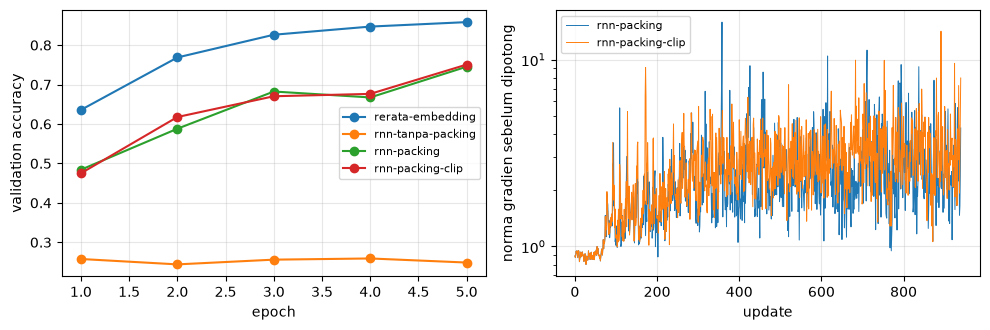

In [15]:
# Langkah 12: dua panel grafik.
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for label, r in kurva.items():
    ax[0].plot(range(1, EPOCH + 1), r['val_acc'], marker='o', label=label)
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('validation accuracy')
ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)

for label in ('rnn-packing', 'rnn-packing-clip'):
    ax[1].plot(kurva[label]['grad_norm'], lw=0.7, label=label)
ax[1].set_xlabel('update'); ax[1].set_ylabel('norma gradien sebelum dipotong')
ax[1].set_yscale('log'); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## F. Akurasi menurut panjang teks · Terbimbing

In [16]:
# Langkah 14: akurasi per golongan panjang untuk model terbaik (panjang 60).
kandidat = [c for c in hasil if c['panjang_maks'] == 60]
juara = max(kandidat, key=lambda c: c['val_acc'])['run_id']
model = simpan[juara]

@torch.no_grad()
def prediksi(model, ds):
    model.eval()
    p, t = [], []
    for xb, lb, yb in loader(ds, 256, False):
        p.append(model(xb.to(DEVICE), lb).argmax(1).cpu()); t.append(yb)
    return torch.cat(p), torch.cat(t)

pred, target = prediksi(model, ds_val)
golongan = pd.cut(L_val.numpy(), bins=[0, 19, 40, MAKS],
                  labels=['<20', '20-40', '>40'])
ringkas = (pd.DataFrame({'golongan': golongan, 'benar': (pred == target).numpy()})
           .groupby('golongan', observed=True)['benar']
           .agg(['mean', 'size']).rename(columns={'mean': 'akurasi', 'size': 'jumlah'}))
print(f'model terbaik: {juara}')
print(ringkas.to_string())

model terbaik: rerata-embedding
          akurasi  jumlah
golongan                 
<20        0.8235      34
20-40      0.8524    1735
>40        0.8676    1231


### Membaca tabel golongan

Dugaan awal bergantung pada model terbaik. Untuk rerata embedding, akurasi diduga naik seiring panjang: teks yang lebih panjang memuat lebih banyak kata penanda topik, dan model tidak perlu membawa informasi melewati banyak langkah. Untuk RNN polos, teks panjang justru rawan karena informasi dari token awal, yang sering berasal dari judul, harus bertahan melewati puluhan pembaruan keadaan. Bandingkan tabel dengan dugaan yang sesuai model terbaik, dan baca kolom `jumlah` sebelum menyimpulkan: golongan `<20` biasanya hanya berisi puluhan contoh, sehingga satu atau dua kesalahan sudah menggeser akurasinya beberapa poin.

## Latihan Mandiri di Lab

Ulangi run terbaik dengan panjang maksimum 30 token, lalu bandingkan dengan 60 token pada arsitektur dan seed yang sama. Sebelum menjalankan, tuliskan prediksi Anda tentang perubahan akurasi dan waktu per epoch. Jelaskan golongan panjang mana yang paling terdampak pemotongan tersebut.

Tuliskan prediksi, hasil, dan perbandingannya di `latihan-07.md`, lalu kumpulkan lewat tugas **Latihan Mandiri di Lab — Modul 07**.

**Prediksi:** 
Dengan asumsi run terbaik di tabel E tetap rerata-embedding (tanpa clip), akurasi validasi pada 30 token turun tipis, sekitar 0,5-1,5 poin persen dari run 60 token, karena judul dan kalimat pembuka sudah memuat sebagian besar kata penanda topik; yang terbuang hanya bagian ekor teks. Waktu per epoch hampir tidak berubah (selisih paling banyak sekitar 10%), sebab model rerata tidak punya langkah rekuren dan biaya utamanya adalah pembaruan Adam atas tabel embedding yang ukurannya tidak bergantung pada panjang deret. (Bila yang terbaik ternyata RNN, waktu per epoch diperkirakan turun mendekati separuh.) Golongan paling terdampak: >40, karena kehilangan paling banyak token; golongan <20 tidak terpotong sama sekali sehingga inputnya identik, dan 20-40 hanya terpotong sebagian.

In [17]:
# 1. Run terbaik dari tabel bagian E (model dan clip yang sama), hanya run 60 token.
tabel_e = pd.DataFrame(hasil)
tabel_e = tabel_e[tabel_e['panjang_maks'] == 60]
terbaik = tabel_e.loc[tabel_e['val_acc'].idxmax()]
label_terbaik = terbaik['run_id']
clip_terbaik = None if terbaik['clip'] == 'tidak' else float(terbaik['clip'])
pabrik = {'rerata-embedding': RerataEmbedding,
          'rnn-tanpa-packing': lambda: ModelRNN(False),
          'rnn-packing': lambda: ModelRNN(True),
          'rnn-packing-clip': lambda: ModelRNN(True)}
print(f'run terbaik: {label_terbaik} | clip: {clip_terbaik} | val_acc: {terbaik["val_acc"]:.4f}')

# 2. Bangun ulang (X, panjang) dengan MAKS=30; ke_indeks membaca MAKS global.
MAKS = 30
try:
    X30_latih, L30_latih = ke_indeks(teks_latih)
    X30_val, L30_val = ke_indeks(teks_val)
finally:
    MAKS = 60                                             # kembalikan ke protokol
assert MAKS == 60 and X30_latih.shape == (12_000, 30) and X30_val.shape == (3_000, 30)
ds30_latih = TensorDataset(X30_latih, L30_latih, torch.tensor(y_latih))
ds30_val = TensorDataset(X30_val, L30_val, torch.tensor(y_val))
print(f'contoh validasi yang terpotong (>30 token): {(L_val > 30).float().mean():.1%}')

# 3. Latih ulang: arsitektur, clip, seed, dan anggaran update sama; hanya MAKS yang berbeda.
model30, kurva30, c30 = jalankan(pabrik[label_terbaik](), f'{label_terbaik}-maks30',
                                 clip_terbaik, ds_tr=ds30_latih, ds_va=ds30_val)
c60 = next(c for c in hasil if c['run_id'] == label_terbaik)
assert c30['n_update'] == c60['n_update'], 'anggaran update harus sama'

perbandingan = pd.DataFrame([c60, c30])[['run_id', 'panjang_maks', 'parameter', 'n_update',
                                         'val_loss', 'val_acc', 'detik_per_epoch']]
print(perbandingan.to_string(index=False))
print(f"selisih val_acc (30 - 60): {c30['val_acc'] - c60['val_acc']:+.4f} | "
      f"rasio waktu per epoch (30 / 60): {c30['detik_per_epoch'] / c60['detik_per_epoch']:.2f}")

# 4. Akurasi per golongan panjang pada contoh yang sama (golongan dari L_val pada MAKS=60).
pred60, target60 = prediksi(simpan[label_terbaik], ds_val)
pred30, target30 = prediksi(model30, ds30_val)
assert (target60 == target30).all(), 'urutan contoh validasi harus sama'
golongan30 = pd.cut(L_val.numpy(), bins=[0, 19, 40, 60], labels=['<20', '20-40', '>40'])
ringkas30 = (pd.DataFrame({'golongan': golongan30,
                           'benar_60': (pred60 == target60).numpy(),
                           'benar_30': (pred30 == target30).numpy()})
             .groupby('golongan', observed=True)
             .agg(jumlah=('benar_60', 'size'), akurasi_60=('benar_60', 'mean'),
                  akurasi_30=('benar_30', 'mean')))
ringkas30['selisih'] = ringkas30['akurasi_30'] - ringkas30['akurasi_60']
print(ringkas30.to_string())
paling = ringkas30['selisih'].idxmin()
print(f'golongan dengan penurunan terbesar: {paling} ({ringkas30.loc[paling, "selisih"]:+.4f})')



run terbaik: rerata-embedding | clip: None | val_acc: 0.8583
contoh validasi yang terpotong (>30 token): 82.5%
                 run_id  panjang_maks  parameter  n_update  val_loss  val_acc  detik_per_epoch
       rerata-embedding            60    1697804       940    0.4253   0.8583           6.5581
rerata-embedding-maks30            30    1697804       940    0.4589   0.8453           6.3352
selisih val_acc (30 - 60): -0.0130 | rasio waktu per epoch (30 / 60): 0.97
          jumlah  akurasi_60  akurasi_30  selisih
golongan                                         
<20           34      0.8235      0.7941  -0.0294
20-40       1735      0.8524      0.8530   0.0006
>40         1231      0.8676      0.8359  -0.0317
golongan dengan penurunan terbesar: >40 (-0.0317)


### Hasil dan perbandingan dengan prediksi

**Jawaban:** Run terbaik pada tabel bagian E adalah `rerata-embedding` tanpa clip dengan val_acc 0,8583. Model ini dilatih ulang dengan `MAKS=30` memakai arsitektur, seed, dan anggaran 940 update yang sama, sehingga hanya panjang maksimum yang berbeda. Pada pemotongan ini, 82,5% contoh validasi kehilangan sebagian token.

Akurasi validasi turun dari 0,8583 menjadi 0,8453, yaitu turun 1,30 poin persen, dan val_loss naik dari 0,4253 menjadi 0,4589. Hasil ini sesuai prediksi, baik arahnya maupun besarnya, karena penurunannya berada di dalam rentang 0,5-1,5 poin yang saya perkirakan. Penurunannya kecil walaupun mayoritas contoh terpotong, sebab 30 token pertama, yaitu judul dan kalimat pembuka, sudah memuat sebagian besar kata penanda topik. Model rerata embedding hanya merata-ratakan vektor kata, sehingga kata di ekor teks yang hilang hanya mengurangi sedikit informasi.

Waktu per epoch turun dari 6,56 detik menjadi 6,34 detik, atau rasio 0,97, jadi hanya berkurang sekitar 3%. Ini juga sesuai prediksi bahwa waktu hampir tidak berubah. Model rerata embedding tidak memiliki langkah rekuren, dan biaya utamanya adalah pembaruan Adam atas tabel embedding sekitar 1,7 juta parameter yang ukurannya tidak bergantung pada panjang deret. Jumlah parameter kedua run pun sama, yaitu 1.697.804.

Golongan panjang yang paling terdampak adalah `>40`, dengan akurasi turun dari 0,8676 menjadi 0,8359, atau turun 3,17 poin. Golongan ini kehilangan token paling banyak, lebih dari 10 token per contoh, sehingga rerata embedding-nya memuat lebih sedikit kata penanda topik. Golongan `20-40` hampir tidak berubah (0,8524 menjadi 0,8530) karena token yang hilang pada contoh 31-40 token hanya sedikit. Golongan `<20` turun 2,94 poin (0,8235 menjadi 0,7941), tetapi penurunan ini tidak dapat dikaitkan dengan pemotongan, karena teks di golongan ini lebih pendek dari 30 token sehingga inputnya identik pada kedua run. Selisihnya berasal dari perbedaan hasil pelatihan, dan golongan ini hanya berisi 34 contoh, sehingga selisih tersebut setara satu contoh (28 menjadi 27 benar). Dengan demikian, prediksi bahwa golongan `>40` paling terdampak dan `<20` tidak terpotong terbukti benar.

Hasil ini berasal dari satu seed, sehingga selisih 1,3 poin belum tentu stabil bila seed diganti.

## G. Run tambahan - bagian dari 25 poin · Tugas Individu

In [18]:
# TODO 13: dua run panjang maksimum (MAKS=30 dan MAKS=60) dan
#          dua run ukuran keadaan (hidden=64 dan 128), seluruhnya pada
#          konfigurasi terbaik. Tambahkan ke daftar `hasil`.
#          Petunjuk: untuk MAKS=30, bangun ulang X dan L dengan ke_indeks.
raise NotImplementedError

tabel = pd.DataFrame(hasil)
print(tabel[['run_id', 'panjang_maks', 'hidden', 'val_acc',
             'detik_per_epoch']].to_string(index=False))
assert len(tabel) >= 7, 'minimal empat run inti ditambah run tambahan'

NotImplementedError: 

In [ ]:
# TODO 15: simpan seluruh run ke metrics.csv.
tabel.insert(0, 'module', 'M07')
tabel.insert(1, 'student_id', NIM)
tabel.to_csv(f'M07_{NIM}_metrics.csv', index=False)
print(f'{len(tabel)} baris tersimpan')

## H. Pertanyaan analisis - bagian dari 10 poin · Tugas Individu

1. Berapa selisih akurasi RNN dengan dan tanpa pengemasan, dan mengapa kesalahan itu tidak melempar galat? TODO
2. Apakah RNN mengalahkan pembanding rerata embedding? Bila selisihnya kecil, apa artinya? TODO
3. Berapa persen parameter ada di tabel embedding, dan apa yang mengubah angka itu? TODO
4. Bagaimana perbandingan norma gradien dengan dan tanpa pemotongan, dan apakah akurasinya berubah? TODO
5. Golongan panjang mana yang paling banyak salah, dan apa dugaan penyebabnya? TODO

## Checklist sebelum mengumpulkan

- [ ] Identitas, seed, device, dan ukuran vocabulary tercantum.
- [ ] Vocabulary dibangun dari subset latih saja.
- [ ] Panjang asli disimpan sebelum pembantalan.
- [ ] Selisih `H[:, -1]` lawan `h_n` dilaporkan sebagai angka.
- [ ] Norma gradien dicatat sebelum pemotongan.
- [ ] Pembanding rerata embedding disertakan.
- [ ] `metrics.csv` memuat seluruh run.
- [ ] Notebook lolos *Restart Kernel and Run All*.